# The Calculus 1 Extra - 04. Calculus 1 Extra Practice with Integrals - Vol 2


<img src="./pics/cover.png" width=300> 

In [1]:
import setuptools

print("setuptools version:", setuptools.__version__)  # Should be < 70.0.0

import vpython as vp
from astropy import units as u
from astropy import constants as const
import sympy as sp
import numpy as np
from IPython.display import display, Math
import matplotlib.pyplot as plt
import sys
from pathlib import Path

print("All imports succeeded!")

setuptools version: 69.5.1


<IPython.core.display.Javascript object>

All imports succeeded!


In [2]:
!python --version

Python 3.13.13


In [3]:
pwd

'c:\\Users\\crodr\\Tutoriales\\Math\\Math_Tutor_DVD_Review\\Calculus_1_Extra_Practice\\04. Calculus 1 Extra Practice with Integrals - Vol 2'

In [4]:
C, n = sp.symbols("C, n", positive=True)
V, A, r, t, x, y, z, theta = sp.symbols("V, A, r, t, x, y, z, theta", real=True)
f, g, h = sp.symbols("f, g, h", cls=sp.Function)

In [5]:
# Add root folder to sys.path
sys.path.append(str(Path("../..").resolve()))

# Import your helper function directly
from helper_functions import fmt_vec, setup_math_axes


## Video 08. Calculating Volume with the Washer Method, Part 2


Given two equations that cross each either, we are asked to calculate the volume of the enclosed region when revolves around the x-axis.

Solution:

1. First we have to find out the crossing points $[x_a, x_b]$, at x-asis. Those are the limits of integration.

2. Then with the washer metod, integrate the volume between this crossing points $[x_a, x_b]$

### Exercise 1
Volume using washer method, of the enclosed region

$$y_1 = \frac{1}{2}x^2+3   \quad y_2 = 12 - \frac{1}{2}x^2 $$

In [ ]:
# Find the crossing points at x-asix, (limits of integration)
y_1 = sp.Rational(1, 2) * x**2 + 3
y_2 = 12 - sp.Rational(1, 2) * x**2

# --- fjind out the crossing points at x-axis ---
eq_1 = sp.Eq(y_1, y_2)
sols = sp.solve(eq_1, x)
limit_a, limit_b = sols

# --- display results ---
display(Math(rf"y_1 = {sp.latex(y_1)}"))
display(Math(rf"y_2 = {sp.latex(y_2)}"))
display(Math(rf"{sp.latex(eq_1)}"))

display(Math(rf"solutions = {sp.latex(sols)}"))
display(Math(rf"\text{{limits of integration: }} a= {limit_a}, b = {limit_b}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [ ]:
# washer method

V = sp.Integral(sp.pi * ((y_1) ** 2 - (y_2) ** 2), (x, limit_a, limit_b))
answer = V.doit().factor()
display(Math(rf"y_1 = {sp.latex(y_1)}"))
display(Math(rf"y_2 = {sp.latex(y_2)}"))

display(Math(rf"{sp.latex(V)} = {sp.latex(answer)}"))

print(
    f"NB: the -sign means that the curves are reversed in the integration, the real volume is: "
)
display(Math(rf"\text{{Real Volume: }} {sp.latex(-answer)}"))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

NB: the -sign means that the curves are reversed in the integration, the real volume is: 


<IPython.core.display.Math object>

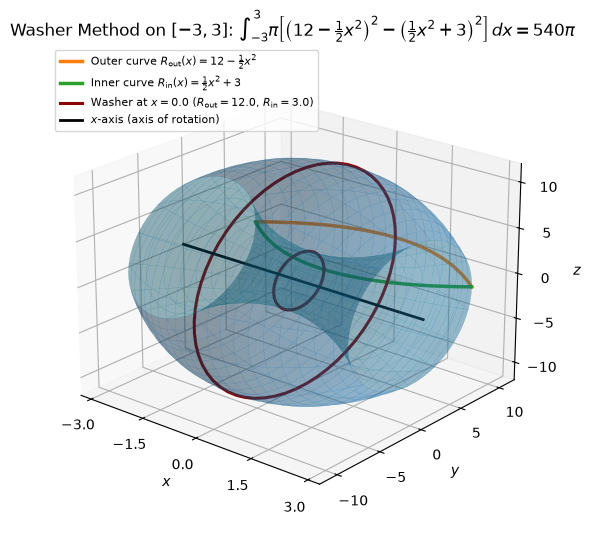

In [26]:
# Symbolic curves on [-3, 3]
x = sp.Symbol("x", real=True)
y1_sym = sp.Rational(1, 2) * x**2 + 3  # Inner radius on [-3, 3]
y2_sym = 12 - sp.Rational(1, 2) * x**2  # Outer radius on [-3, 3]

y_in_num = sp.lambdify(x, y1_sym, "numpy")
y_out_num = sp.lambdify(x, y2_sym, "numpy")

# Grid for solid of revolution around the x-axis: x in [-3, 3], theta in [0, 2*pi]
x_vals = np.linspace(-3.0, 3.0, 80)
theta_vals = np.linspace(0.0, 2.0 * np.pi, 60)
X, THETA = np.meshgrid(x_vals, theta_vals)

R_out = y_out_num(X)
R_in = y_in_num(X)

# Outer surface coordinates
Y_out = R_out * np.cos(THETA)
Z_out = R_out * np.sin(THETA)

# Inner hollow bore surface coordinates
Y_in = R_in * np.cos(THETA)
Z_in = R_in * np.sin(THETA)

r_max = float(np.max(R_out))
bound = np.ceil(r_max)

fig = plt.figure(figsize=(8.5, 5.5))
ax = fig.add_subplot(111, projection="3d")

# Plot outer surface and inner hollow bore
ax.plot_surface(
    X,
    Y_out,
    Z_out,
    color="tab:blue",
    alpha=0.28,
    edgecolor="tab:blue",
    linewidth=0.2,
    rstride=4,
    cstride=4,
)
ax.plot_surface(
    X,
    Y_in,
    Z_in,
    color="tab:cyan",
    alpha=0.22,
    edgecolor="darkcyan",
    linewidth=0.2,
    rstride=4,
    cstride=4,
)

# Highlight outer and inner generating curves in the x-y plane (z = 0)
ax.plot(
    x_vals,
    y_out_num(x_vals),
    np.zeros_like(x_vals),
    color="tab:orange",
    linewidth=2.5,
    label=r"Outer curve $R_{\mathrm{out}}(x) = 12 - \frac{1}{2}x^2$",
)
ax.plot(
    x_vals,
    y_in_num(x_vals),
    np.zeros_like(x_vals),
    color="tab:green",
    linewidth=2.5,
    label=r"Inner curve $R_{\mathrm{in}}(x) = \frac{1}{2}x^2 + 3$",
)

# Highlight a representative washer slice at x = 0.0 (where gap is widest)
x_washer = 0.0
r_o = float(y_out_num(x_washer))
r_i = float(y_in_num(x_washer))

ax.plot(
    np.full_like(theta_vals, x_washer),
    r_o * np.cos(theta_vals),
    r_o * np.sin(theta_vals),
    color="darkred",
    linewidth=2.2,
    label=rf"Washer at $x = {x_washer:.1f}$ ($R_{{\mathrm{{out}}}} = {r_o:.1f}$, $R_{{\mathrm{{in}}}} = {r_i:.1f}$)",
)
ax.plot(
    np.full_like(theta_vals, x_washer),
    r_i * np.cos(theta_vals),
    r_i * np.sin(theta_vals),
    color="darkred",
    linewidth=2.2,
)

# Axis of revolution (x-axis)
ax.plot(
    [-3.3, 3.3],
    [0, 0],
    [0, 0],
    color="black",
    linewidth=2,
    label=r"$x$-axis (axis of rotation)",
)

ax.set_xlim(-3.3, 3.3)
ax.set_ylim(-bound, bound)
ax.set_zlim(-bound, bound)
ax.set_xticks([-3.0, -1.5, 0.0, 1.5, 3.0])
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_zlabel(r"$z$")
ax.set_title(
    r"Washer Method on $[-3, 3]$: $\int_{-3}^{3} \pi\left[\left(12-\frac{1}{2}x^2\right)^2 - \left(\frac{1}{2}x^2+3\right)^2\right]\,dx = 540\pi$"
)
ax.view_init(elev=22, azim=-50)
ax.legend(loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()